# Basic Verification Workflow

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import string
import sys

import re

from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer

import logging

logging.basicConfig(level="INFO")
logger = logging.getLogger("ruzicka")

import mpl_fontkit as fk

fk.install("Roboto Condensed")

from ruzicka.BDIVerifier import BDIVerifier

Font name: `Roboto Condensed`


## Preprocessing

We have supplied a basic preprocessing script that expects plain textfiles. It is no frills - it will read every file in the given directory, lowercase and remove punctuation, and split each file into 1000 word chunks (to increase the number of comparison samples). Chunking the texts this way also gives us a better feel for the internal variation within a text.


In [3]:
#We could or could not remove the rex declination, I've left it here for now

#def _remove_rex_declination(text: str) -> str:
    # List of declinations of "rex"
    #rex_forms = [
        #"rex", "regis", "regi", "regem", "rege", 
        #"reges", "regum", "regibus"
    #]
    #pattern = r'\b(?:' + '|'.join(rex_forms) + r')\b'
    #return re.sub(pattern, "", text, flags=re.IGNORECASE).strip()

# Before writing this code, I had already preprocessed the texts in the .txt files:
# lowercasing, removing punctuation, and replacing all occurrences of -ae with -e, j- with i-, and -v- with -u.
# We could  include this last step here, although it would not make a difference, just for completeness.
def _preprocess_text(text: str) -> str:
    text = text.translate(str.maketrans("", "", string.punctuation))
    #text = _remove_rex_declination(text)
    return text

def _overlapping_samples(text: str, sample_size, overlap_ratio: int) -> list[list[str]]:
    txt_ary: list[str] = text.split()
    num_samples = len(txt_ary) // (sample_size // overlap_ratio)
    step = sample_size // overlap_ratio
    samples = [txt_ary[i * step : (i * step) + sample_size] for i in range(num_samples)]
    return samples


def preprocess_and_slice_text_files(
    folder_path: str, sample_size: int = 1000, overlap_ratio: int = 1
) -> pd.DataFrame:
    """
    Preprocess a set of text samples. Files are lowercased, split into words,
    and then broken into chunks of the selected size (default 1000 words)

    In:
        folder_path (string): Folder to read for text files. Reads all files
            with a .txt extension.
        sample_size (int=1000): Number of words per chunk. Words at the end of
            the file that do not make a full chunk are discarded.
        overlap_ratio (int=1): Amount of overlap, higher is more overlap. A
            ratio of two advances the rolling window by half of the sample_size.

    Returns:
        dict[str,list]: The results. Each chunk will by indexed by a name
            constructed from the filename with the chunk number, e.g. MyFile.txt
            will produce MyFile_0, MyFile_1 ... The words in the chunk are
            returned as a list.

    """
    processed_texts = {}
    for filename in os.listdir(folder_path):
        if filename.endswith(".txt"):
            with open(
                os.path.join(folder_path, filename), "r", encoding="latin-1"
            ) as file:
                text = file.read()
                processed_text = _preprocess_text(text)
                samples = _overlapping_samples(
                    processed_text, sample_size, overlap_ratio
                )
                num_samples = len(samples)
                for i, sample in enumerate(samples):
                    variable_name = filename[:-4] + "_" + str(i)
                    processed_texts[variable_name] = sample
            logging.info(
                f"'{filename}' was processed and split into {num_samples} samples"
            )

    entries = []
    for k, txt in processed_texts.items():
        chunk = " ".join(txt)
        entries.append(
            {
                "tag": k,
                "chunk": chunk,
            }
        )
    chunk_df = pd.DataFrame(entries)

    return chunk_df

raw_df = preprocess_and_slice_text_files("data", sample_size=2000)
print(raw_df)

INFO:root:'NLC_miracmar.txt' was processed and split into 8 samples
INFO:root:'BM_regum.txt' was processed and split into 3 samples
INFO:root:'BB_adelcom.txt' was processed and split into 4 samples
INFO:root:'OM_ernestus.txt' was processed and split into 11 samples
INFO:root:'BBi_specul.txt' was processed and split into 6 samples
INFO:root:'SR_dracnorma.txt' was processed and split into 13 samples
INFO:root:'RT_epistul.txt' was processed and split into 8 samples
INFO:root:'RL_vitaans.txt' was processed and split into 22 samples
INFO:root:'M_epist.txt' was processed and split into 5 samples
INFO:root:'NLC_specstult.txt' was processed and split into 12 samples
INFO:root:'X_liberregum.txt' was processed and split into 11 samples
INFO:root:'M_tobias.txt' was processed and split into 6 samples
INFO:root:'SAC_excidtroi.txt' was processed and split into 3 samples
INFO:root:'U1_pyram.txt' was processed and split into 3 samples
INFO:root:'H_carmmin.txt' was processed and split into 2 samples
IN

                tag                                              chunk
0    NLC_miracmar_0  uirginis et matris celebri memoranda relatu sc...
1    NLC_miracmar_1  quod me mouet amplius illud quod male demonibu...
2    NLC_miracmar_2  limen erat furibundus et hostis et ignis uirib...
3    NLC_miracmar_3  fugam sed uariando dolum canis ementita figura...
4    NLC_miracmar_4  singula uera fore dixerat at cuncti communi uo...
..              ...                                                ...
350    U2_ysengr_15  in laqueum stultus ducente doloso ludus inequa...
351    U2_ysengr_16  erratque pauetque sicut in externis per loca n...
352    U2_ysengr_17  enim sex ouibus quondam sumptis illectus ad es...
353    U2_ysengr_18  taliter hec retines debita tamque diu quot tu ...
354    U2_ysengr_19  sic ubi sacrantur templa uetusta canunt hoc gr...

[355 rows x 2 columns]


## Extract metadata from filename


In [15]:
def splitfunc(x: pd.Series) -> list[str]:
    author, text, chunk_number = x.tag.split("_")  # Dividi la stringa in 4 parti 
    
    return [author, text, chunk_number]

tmp = raw_df.apply(
    splitfunc,
    axis=1,
    result_type="expand",
)

raw_df.insert(0, "author", tmp[0])  
raw_df.insert(1, "text", tmp[1])   
raw_df.insert(2, "chunk_number", tmp[2])

raw_df

,author,text,chunk_number,tag,chunk
0,NLC,miracmar,0,NLC_miracmar_0,uirginis et matris celebri memoranda relatu sc...
1,NLC,miracmar,1,NLC_miracmar_1,quod me mouet amplius illud quod male demonibu...
2,NLC,miracmar,2,NLC_miracmar_2,limen erat furibundus et hostis et ignis uirib...
3,NLC,miracmar,3,NLC_miracmar_3,fugam sed uariando dolum canis ementita figura...
4,NLC,miracmar,4,NLC_miracmar_4,singula uera fore dixerat at cuncti communi uo...
...,...,...,...,...,...
350,U2,ysengr,15,U2_ysengr_15,in laqueum stultus ducente doloso ludus inequa...
351,U2,ysengr,16,U2_ysengr_16,erratque pauetque sicut in externis per loca n...
352,U2,ysengr,17,U2_ysengr_17,enim sex ouibus quondam sumptis illectus ad es...
353,U2,ysengr,18,U2_ysengr_18,taliter hec retines debita tamque diu quot tu ...


## Factorizing

The BDI code will need numeric labels. The simplest way to get this is using pandas built-in `factorize()` method

In [18]:
print(raw_df["author"].unique())

['NLC' 'BM' 'BB' 'OM' 'BBi' 'SR' 'RT' 'RL' 'M' 'X' 'SAC' 'U1' 'H' 'PDE'
 'ASt' 'HA' 'AE' 'U3' 'H?' 'EM' 'HW' 'BS' 'RDV' 'PE' 'IS' 'QS' 'ASu' 'OSE'
 'PR' 'HM' 'U2']


In [20]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()
labels = label_encoder.fit_transform(raw_df["author"])
raw_df.insert(1, "author_label", labels)

## Vectorizing

Latin function words have multiple spelling variants. We will  need **a single X dataframe with one numeric vector per sample**. Here it will be (eventually) z-scaled function word frequencies.

In [6]:
# regarding what's written above: I don't really get what we're doing here. Spelling variants just for the function words?
 
v = TfidfVectorizer(use_idf=True, analyzer="char", ngram_range=(7,9),
                    decode_error="replace", norm="l2", max_features=10000)
v.fit(raw_df.chunk)

def vectorize(s):
    X = v.transform([s])
    df = pd.DataFrame(X.toarray())
    df.columns = v.get_feature_names_out()

    stops_dict = {}
    
    for ary in stops:
        ary = sorted(list(set(ary)))
        stops_dict[ary[0]] = df[df.columns.intersection(ary)].sum(axis=1)
    
    stops_df_combined = pd.DataFrame(stops_dict)
    
    return stops_df_combined

NameError: name 'raw_df' is not defined

> NOTE: This X dataframe is NOT YET SCALED. Because we will use z-scaling, it is methodologically more sound to fit the scaler on the comparison set, and then scale the problems using the fitted scaler (so no frequency information about the problems leaks into the z-scores)

In [87]:
X = pd.DataFrame(v.transform(raw_df.chunk).toarray()).reset_index(drop=True)
X

,0,1,2,3,4,5,6,7,8,9,...,9990,9991,9992,9993,9994,9995,9996,9997,9998,9999
0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.014829,...,0.011060,0.012019,0.014114,0.0,0.010811,0.011775,0.0,0.000000,0.0,0.0
1,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.010249,...,0.000000,0.000000,0.009755,0.0,0.000000,0.008138,0.0,0.000000,0.0,0.0
2,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,...,0.011147,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0
3,0.0,0.0,0.0,0.000000,0.039479,0.039479,0.000000,0.0,0.000000,0.000000,...,0.000000,0.000000,0.014215,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0
4,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.013684,...,0.000000,0.000000,0.000000,0.0,0.000000,0.021732,0.0,0.000000,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
351,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.016225,0.0,0.017436,0.009096,...,0.013568,0.014745,0.000000,0.0,0.013263,0.014446,0.0,0.000000,0.0,0.0
352,0.0,0.0,0.0,0.000000,0.030685,0.030685,0.000000,0.0,0.000000,0.017412,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0
353,0.0,0.0,0.0,0.012299,0.013854,0.013854,0.014023,0.0,0.000000,0.015723,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.0,0.0
354,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.008211,...,0.012248,0.013310,0.000000,0.0,0.011973,0.000000,0.0,0.015018,0.0,0.0


## Scaling

Now that we have split, we can fit the scaler on just the comparison set, and scale both the problems and the comparison data...

In [91]:
scaler = StandardScaler(with_mean=False).fit(X)
X_scaled = scaler.transform(X)

## Verification

Now it is time to do the verification! Here we will perform 1000 bootstrap iterations per sample, using the Ruzicka (minmax) metric, as promoted in the following paper: Kestemont, M., Stover, J., Koppel, M., Karsdorp, K. & Daelemans, W., ‘Authenticating the writings of Julius Caesar’. In: Expert Systems with Applications 63 (2016): pp. 86–96.

> BDI is a modification / update based on the `Order2Verifier` code from the paper above

## Verifying against every label

The key method for BDI is `predict_proba()`. It takes a set of problems (from the X array), and a set of labels to test each problem against (candidate label). Here we demonstrate by testing the problem text against every candidate label. Full documentation is available with `help(BDIVerifier.predict_proba)`

In [95]:
problem_X = X_scaled[raw_df.text == "liberregum"].copy()
comparison_X = X_scaled[raw_df.text != "liberregum"].copy()
problem_y = raw_df[raw_df.text == "liberregum"]["author_label"]
comparison_y = raw_df[raw_df.text != "liberregum"]["author_label"]
print(problem_X.shape)
print(problem_y.shape)
print(comparison_X.shape)
print(comparison_y.shape)

rng = np.random.default_rng(42)

bdi_mm = BDIVerifier(
    metric="minmax", nb_bootstrap_iter=1000, rnd_prop=0.33, random_state=rng,
)
bdi_mm.fit(comparison_X, comparison_y)

results = {}

for int_label in set(comparison_y):
    str_label = label_encoder.classes_[int_label]
    print("...... Testing against:", str_label)
    
    try: 
        probas = bdi_mm.predict_proba(problem_X, [int_label] * problem_X.shape[0])
        mean_proba = np.mean(probas)  
        std_proba = np.std(probas)
        print(f"Bootstrap Match Strength (0–1.0):", np.mean(probas))
        print(probas)
        
        results[str_label] = {"mean": mean_proba, "std": std_proba}
    except Exception as e:
        print(f"Error for {str_label}: {e}")

05/04/2025 10:54:53 [ruzicka:INFO] Fitting on 345 documents...
05/04/2025 10:54:53 [ruzicka:INFO] Predicting on 11 documents


(11, 10000)
(11,)
(345, 10000)
(345,)
...... Testing against: AE


05/04/2025 10:54:59 [ruzicka:INFO] Predicting on 11 documents


Bootstrap Match Strength (0–1.0): 0.14627272727272722
[0.131 0.44  0.074 0.068 0.001 0.117 0.212 0.141 0.006 0.373 0.046]
...... Testing against: AS


05/04/2025 10:55:07 [ruzicka:INFO] Predicting on 11 documents


...

Bootstrap Match Strength (0–1.0): 0.026454545454545408
[0.    0.058 0.032 0.003 0.055 0.031 0.04  0.021 0.002 0.041 0.008]
...... Testing against: U1


05/04/2025 10:57:50 [ruzicka:INFO] Predicting on 11 documents


Bootstrap Match Strength (0–1.0): 0.00045454545454545455
[0.    0.005 0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
...... Testing against: U2


05/04/2025 10:57:57 [ruzicka:INFO] Predicting on 11 documents


Bootstrap Match Strength (0–1.0): 0.03399999999999993
[0.008 0.054 0.042 0.061 0.124 0.    0.007 0.012 0.063 0.    0.003]
...... Testing against: U3
Bootstrap Match Strength (0–1.0): 0.0
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


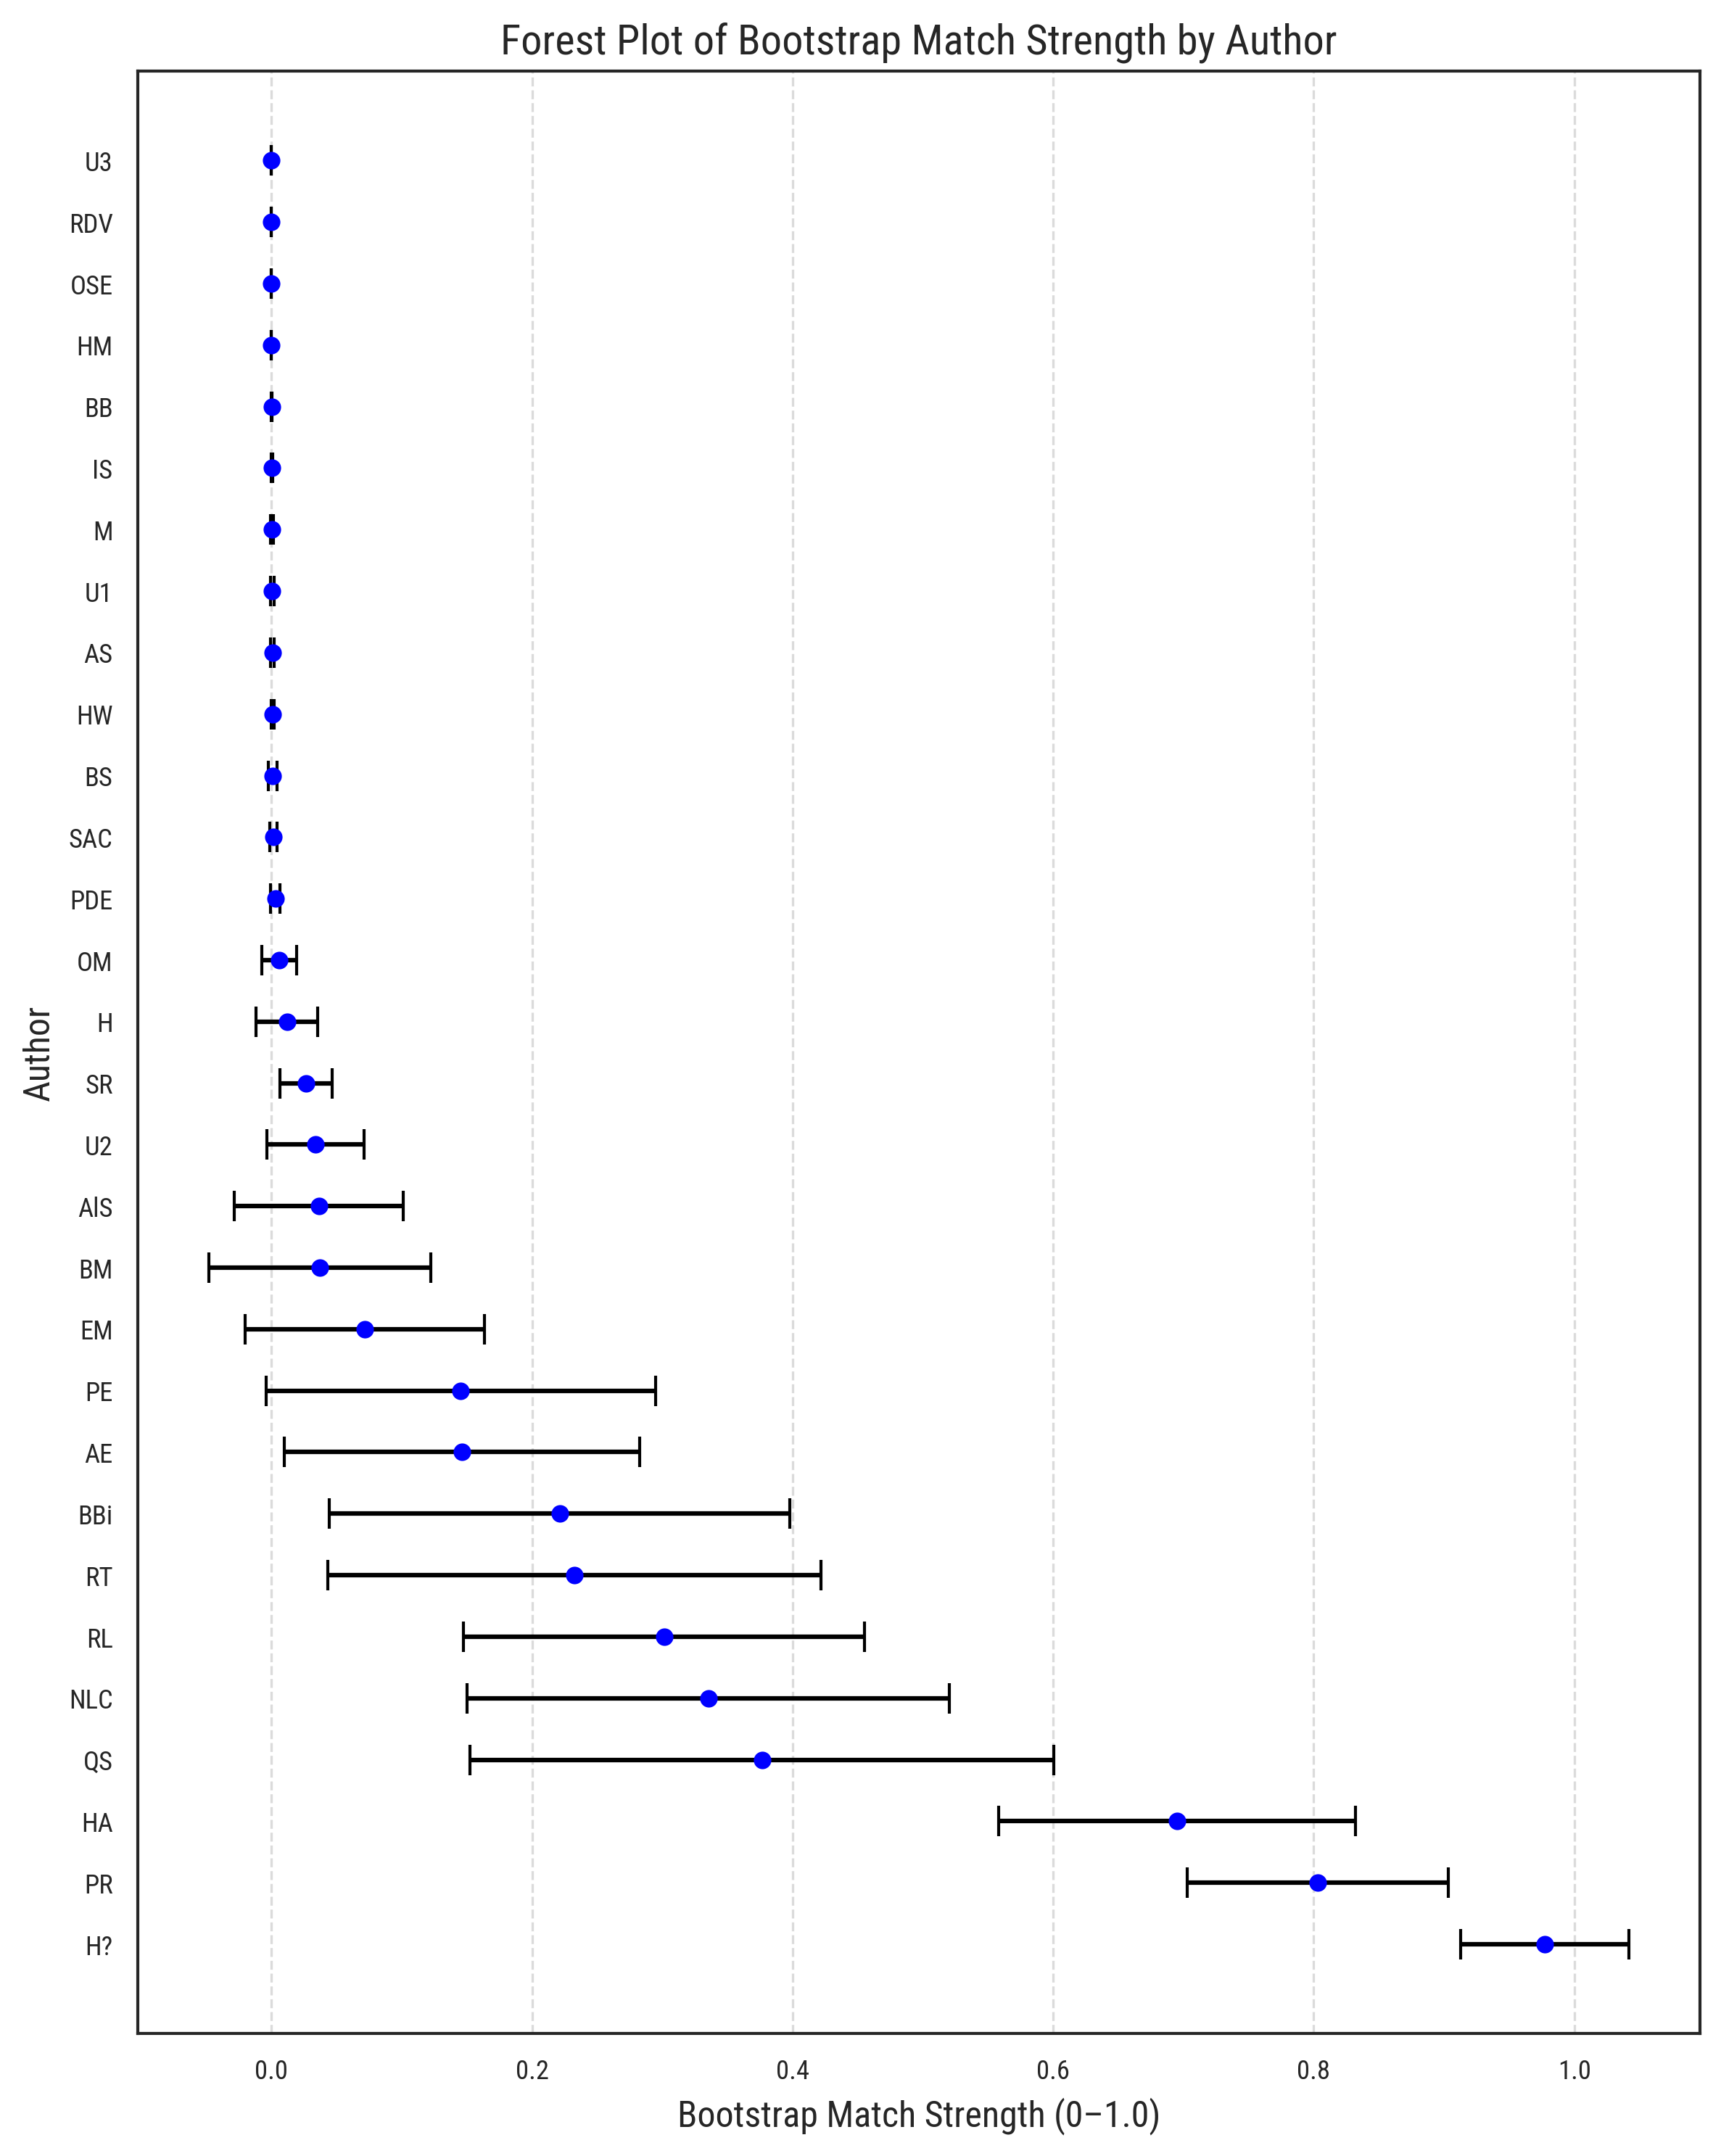

In [96]:
sorted_authors = sorted(results.items(), key=lambda x: x[1]["mean"], reverse=True)

labels = [author[0] for author in sorted_authors]
means = [author[1]["mean"] for author in sorted_authors]
stds = [author[1]["std"] for author in sorted_authors]

plt.figure(figsize=(8, 10))

plt.errorbar(means, labels, xerr=stds, fmt='o', color='blue', ecolor='black', elinewidth=1.5, capsize=5)

plt.xlabel("Bootstrap Match Strength (0–1.0)", fontsize=12)
plt.ylabel("Author", fontsize=12)
plt.title("Forest Plot of Bootstrap Match Strength by Author", fontsize=14)

plt.yticks(rotation=0)

plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Interpretation

The 'match strength' reported is the bootstrap percentile of a metric distance of 0. If the candidate label is *closer* to the bootstrap sample, the distance will be positive, so this is essentially the 'confidence' that the candidate label is the best match. Empirically, confidence values over 0.89 have resulted in very high precision (very few false positives—see the paper). Values below this threshold are *not* reliable negative indicators.

## Chunked Visualisation

One of the strengths of the BDI approach is that it foreground the uncertainty in our determinations. Here we just demonstrate how to visualize the full distribution of bootstrap distances.

At each run for `predict_proba()`, the `_dist_arrays` property is also set, and contains the full bootstrap results (1000 distances per chunk, in this case)

In [107]:
label_index_H = label_encoder.transform(["H"])[0]

bdi_mm.predict_proba(
    problem_X, [label_index_H] * problem_X.shape[0]
)

liberregum_vs_hildebert = pd.DataFrame(dict(zip(raw_df[raw_df.text == "liberregum"].tag, bdi_mm._dist_arrays)))
liberregum_vs_hildebert

05/04/2025 11:00:37 [ruzicka:INFO] Predicting on 11 documents


,X_liberregum_prob_0,X_liberregum_prob_1,X_liberregum_prob_2,X_liberregum_prob_3,X_liberregum_prob_4,X_liberregum_prob_5,X_liberregum_prob_6,X_liberregum_prob_7,X_liberregum_prob_8,X_liberregum_prob_9,X_liberregum_prob_10
0,0.006256,-0.023089,-0.005764,-0.026701,-0.020690,-0.006846,-0.013403,-0.033000,-0.040567,-0.027708,0.007997
1,-0.014922,-0.048357,-0.000334,-0.039177,-0.021471,-0.023275,-0.037075,-0.051240,-0.055301,-0.026990,0.000494
2,-0.007711,-0.038864,-0.014324,-0.033570,-0.039765,-0.005356,-0.017984,-0.028997,-0.030702,-0.016793,-0.007383
3,-0.010709,-0.022185,-0.028678,-0.021945,-0.016299,-0.012458,-0.035259,-0.052097,-0.061017,-0.027726,0.007484
4,-0.013689,-0.039729,-0.031641,-0.035276,-0.034002,-0.011878,-0.034812,-0.057497,-0.060623,-0.021194,-0.020368
...,...,...,...,...,...,...,...,...,...,...,...
995,-0.031213,-0.061333,-0.033082,-0.019755,-0.028469,-0.015326,-0.042725,-0.019351,-0.037904,-0.048858,-0.012507
996,-0.009871,-0.016159,-0.010306,-0.046245,-0.024656,-0.008153,-0.044489,-0.056165,-0.078879,-0.009862,0.000939
997,-0.005617,-0.048712,-0.000899,-0.053157,-0.024694,-0.026014,-0.025673,-0.045986,-0.025632,-0.031392,0.003775
998,-0.039245,-0.038298,-0.024544,-0.032360,-0.027353,-0.033963,-0.031784,-0.028493,-0.041209,-0.005607,-0.018358


## Visualization

Here we use a quick seaborn KDE plot to visualize. To interpret these plots:
- If a distribution is credibly *positive* it indicates that the candidate is the best match  
- If a distribution is *centered around zero* then it is entirely possible that the true producer is not in the candidate set
- If a distribution is credibly *negative* it indicates that one (or more) of the imposter candidates is consistently a better match

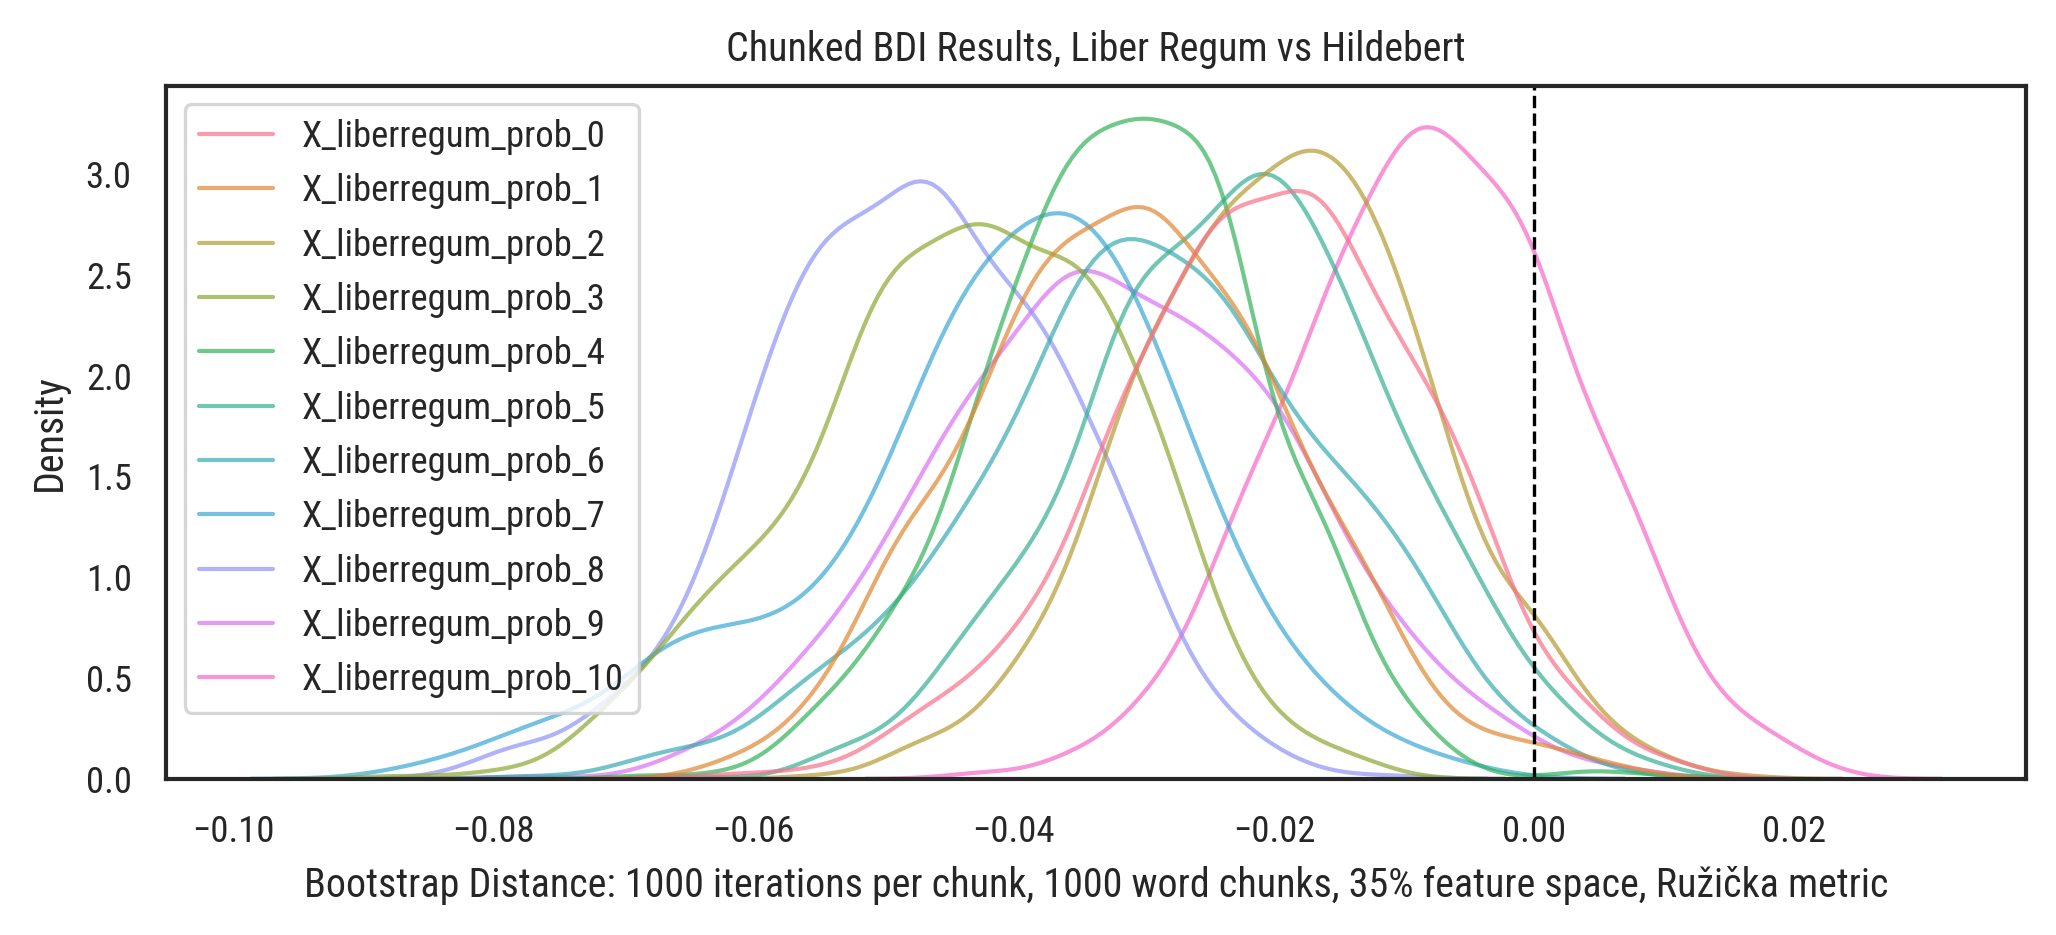

In [117]:
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)
ax = sns.kdeplot(liberregum_vs_hildebert, linewidth=1, alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set(
    xlabel="Bootstrap Distance: 1000 iterations per chunk, 1000 word chunks, 35% feature space, Ružička metric",
    ylabel="Density",
    title="Chunked BDI Results, Liber Regum vs Hildebert",
)
plt.show()

NOTE: The match strength results from BDI are not well balanced (they favour precision, i.e., few false positive matches) so we do not recommend interpreting them as probabilities, and we deliberately avoid framing the (inverse) match-strength as a "bootstrap p-value".

## Alternative Candidate

In [111]:
label_index_M = label_encoder.transform(["M"])[0]

bdi_mm.predict_proba(
    problem_X, [label_index_M] * problem_X.shape[0]
)

liberregum_vs_matthew = pd.DataFrame(dict(zip(raw_df[raw_df.text == "liberregum"].tag, bdi_mm._dist_arrays)))
liberregum_vs_matthew

05/04/2025 11:00:43 [ruzicka:INFO] Predicting on 11 documents


,X_liberregum_prob_0,X_liberregum_prob_1,X_liberregum_prob_2,X_liberregum_prob_3,X_liberregum_prob_4,X_liberregum_prob_5,X_liberregum_prob_6,X_liberregum_prob_7,X_liberregum_prob_8,X_liberregum_prob_9,X_liberregum_prob_10
0,-0.066442,-0.102142,-0.071617,-0.078536,-0.080221,-0.067207,-0.076081,-0.062923,-0.077026,-0.100293,-0.072171
1,-0.089025,-0.087279,-0.087580,-0.085774,-0.102988,-0.071499,-0.092181,-0.082224,-0.080861,-0.111189,-0.064479
2,-0.083350,-0.068442,-0.115456,-0.064544,-0.077799,-0.092162,-0.083619,-0.082285,-0.072331,-0.100798,-0.076622
3,-0.061114,-0.075297,-0.086721,-0.099147,-0.093658,-0.083552,-0.080545,-0.107007,-0.102715,-0.082978,-0.049863
4,-0.084284,-0.070706,-0.078101,-0.073076,-0.087508,-0.088174,-0.086909,-0.094183,-0.061134,-0.101541,-0.076159
...,...,...,...,...,...,...,...,...,...,...,...
995,-0.093699,-0.078509,-0.062573,-0.080483,-0.084961,-0.114571,-0.079218,-0.075210,-0.086645,-0.076443,-0.055388
996,-0.076866,-0.075616,-0.076404,-0.086987,-0.072482,-0.071151,-0.073637,-0.080675,-0.052104,-0.100271,-0.071497
997,-0.086349,-0.081852,-0.081738,-0.070661,-0.090893,-0.060713,-0.068484,-0.084583,-0.086994,-0.106254,-0.045085
998,-0.087361,-0.084410,-0.073914,-0.101754,-0.087703,-0.076430,-0.085876,-0.092895,-0.087168,-0.097686,-0.057167


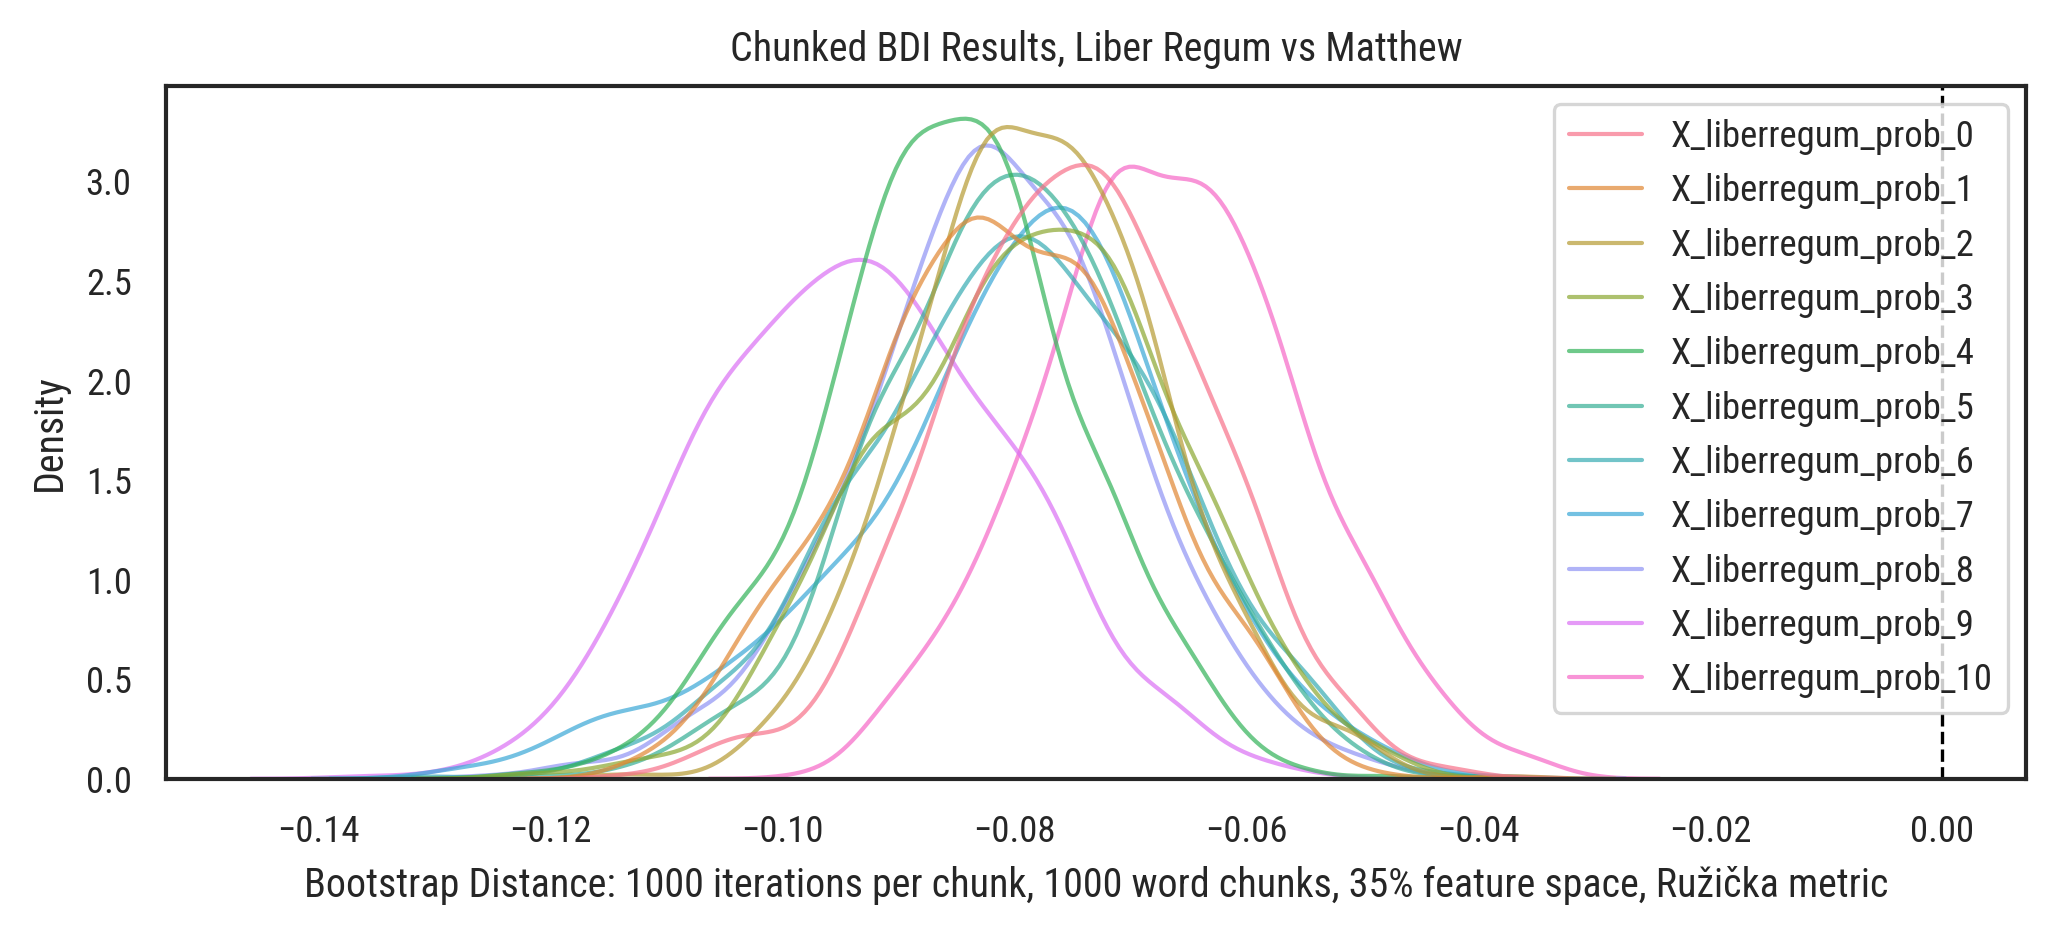

In [112]:
sns.set_theme(
    context="paper",
    font="Roboto Condensed",
    style="white",
    rc={"figure.figsize": (8, 3), "figure.dpi": 300},
)
ax = sns.kdeplot(liberregum_vs_matthew, linewidth=1, alpha=0.7)
ax.axvline(0, color="black", linestyle="--", linewidth=0.8)
ax.set(
    xlabel="Bootstrap Distance: 1000 iterations per chunk, 1000 word chunks, 35% feature space, Ružička metric",
    ylabel="Density",
    title="Chunked BDI Results, Liber Regum vs Matthew",
)
plt.show()